In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from box_utils import BOX_ROOT
print("Using Box root:", BOX_ROOT)

Using Box root: /Users/kurumi/Library/CloudStorage/Box-Box


In [7]:
MANPOWER = BOX_ROOT / "00_one_percent" 
df = pd.read_csv(MANPOWER / "Man_Power_2024_July.csv")
print(df.shape)
df.head()

(188070, 18)


,Unnamed: 0,Manpower_PK,Incident_FK,Address,Area,Audit_Type,Beat,Code,Comment,Manpower_Record_Time,Record_Type,Seconds_At_Status,Unit_Agency,Unit_ID,Unit_Shift,Vehicle,Table_Type,Combined_Text_No_Time
0,536720,"97,793,868",NaN,NaN,NaN,US,NaN,USAV,NaN,2024-07-01 00:25:09,2,172,OP,3L25,NaN,NaN,ManPower,No unit records associated to this incident
1,536730,"97,794,038",NaN,NaN,NaN,US,NaN,USAT,NaN,2024-07-01 00:49:52,2,"1,111",OP,2L11,NaN,NaN,ManPower,No unit records associated to this incident
2,536733,"97,794,060",NaN,NaN,NaN,US,NaN,USAV,NaN,2024-07-01 00:53:21,2,2,OP,2T31,NaN,NaN,ManPower,No unit records associated to this incident
3,536748,"97,794,578","11,584,881",NaN,NaN,US,NaN,FR,NaN,2024-07-01 02:38:18,2,"2,264",OP,3L18,NaN,NaN,ManPower,Unit: 3L18 Status Code: FR Seconds...
4,536760,"97,793,827",NaN,NaN,NaN,US,NaN,USAT,NaN,2024-07-01 00:19:27,2,2,OP,3L76,NaN,NaN,ManPower,No unit records associated to this incident


In [9]:
# Ensure proper types
df['Manpower_Record_Time'] = pd.to_datetime(df['Manpower_Record_Time'])

# Clean numeric values formatted with commas (e.g. '1,111' -> 1111)
if df['Seconds_At_Status'].dtype == 'object':
    df['Seconds_At_Status'] = (
        df['Seconds_At_Status']
        .astype(str)
        .str.replace(',', '', regex=False)
    )
df['Seconds_At_Status'] = pd.to_numeric(df['Seconds_At_Status'], errors='coerce').fillna(0)

# Calculate duration in minutes
df['Minutes_At_Status'] = df['Seconds_At_Status'] / 60.0

# Extract Date and Hour
df['Date'] = df['Manpower_Record_Time'].dt.date
df['Hour'] = df['Manpower_Record_Time'].dt.hour

df.head()

,Unnamed: 0,Manpower_PK,Incident_FK,Address,Area,Audit_Type,Beat,Code,Comment,Manpower_Record_Time,...,Seconds_At_Status,Unit_Agency,Unit_ID,Unit_Shift,Vehicle,Table_Type,Combined_Text_No_Time,Minutes_At_Status,Date,Hour
0,536720,"97,793,868",NaN,NaN,NaN,US,NaN,USAV,NaN,2024-07-01 00:25:09,...,172.0,OP,3L25,NaN,NaN,ManPower,No unit records associated to this incident,2.866667,2024-07-01,0
1,536730,"97,794,038",NaN,NaN,NaN,US,NaN,USAT,NaN,2024-07-01 00:49:52,...,0.0,OP,2L11,NaN,NaN,ManPower,No unit records associated to this incident,0.000000,2024-07-01,0
2,536733,"97,794,060",NaN,NaN,NaN,US,NaN,USAV,NaN,2024-07-01 00:53:21,...,2.0,OP,2T31,NaN,NaN,ManPower,No unit records associated to this incident,0.033333,2024-07-01,0
3,536748,"97,794,578","11,584,881",NaN,NaN,US,NaN,FR,NaN,2024-07-01 02:38:18,...,0.0,OP,3L18,NaN,NaN,ManPower,Unit: 3L18 Status Code: FR Seconds...,0.000000,2024-07-01,2
4,536760,"97,793,827",NaN,NaN,NaN,US,NaN,USAT,NaN,2024-07-01 00:19:27,...,2.0,OP,3L76,NaN,NaN,ManPower,No unit records associated to this incident,0.033333,2024-07-01,0


In [29]:
# ---------------------------------------------------------
# 2. Filter for "Available" Status Codes
# ---------------------------------------------------------
# Typically, USAV (Unit Status Available) and FR (Free) denote availability.
# Check unique codes: print(df['Code'].value_counts())
available_codes = ['USAV', 'FR']
df_avail = df[df['Code'].isin(available_codes)].copy()

# Extract 2-digit Beat code from Unit_ID
df_avail['Beat'] = df_avail['Unit_ID'].str.extract(r'(\d{2})$')[0]

# ---------------------------------------------------------
# Q1: Average # of Minutes Available During a Shift
# ---------------------------------------------------------
# If Unit_Shift is populated:
if df_avail['Unit_Shift'].notna().sum() > 0:
    shift_avail = (
        df_avail.groupby(['Date', 'Unit_ID', 'Unit_Shift'])['Minutes_At_Status']
        .sum()
        .reset_index()
    )
    avg_mins_per_shift = shift_avail['Minutes_At_Status'].mean()
    print(f"Average available minutes per shift: {avg_mins_per_shift:.2f} mins")
else:
    # Fallback if Unit_Shift is largely NaN: aggregate by Unit per Date
    unit_day_avail = (
        df_avail.groupby(['Date', 'Unit_ID'])['Minutes_At_Status']
        .sum()
        .reset_index()
    )
    print(f"Average available minutes per unit/day: {unit_day_avail['Minutes_At_Status'].mean():.2f} mins")

Average available minutes per shift: 0.00 mins



--- Available Minutes per Unit on 2024-07-01 (Top 10) ---
  Unit_ID  Minutes_At_Status
0   11C20          39.900000
1    8C22          36.916667
2    1L31          34.266667
3    1L27          32.400000
4    1D01          28.833333
5    3L13          27.666667
6    1L04          27.316667
7    1L30          23.166667
8    5A52          22.916667
9    1T53          22.283333


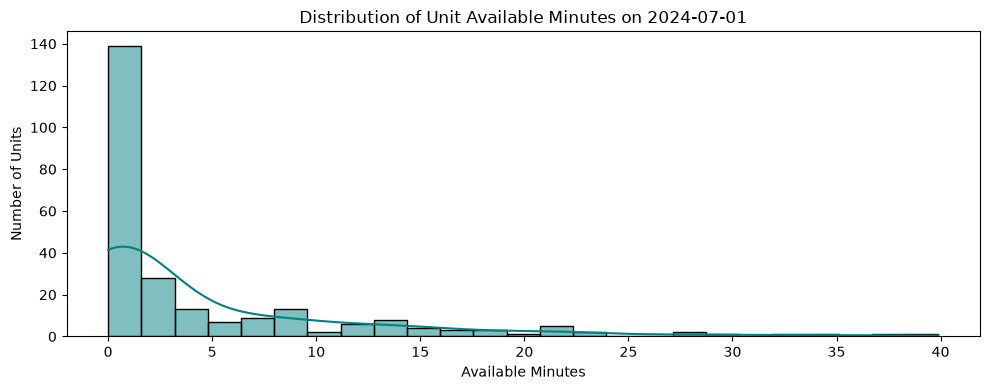

In [11]:
# ---------------------------------------------------------
# Q2: EDA for a Specific Day (Minutes per Unit)
# ---------------------------------------------------------
selected_date = pd.to_datetime('2024-07-01').date()
day_data = df_avail[df_avail['Date'] == selected_date]

unit_avail_day = (
    day_data.groupby('Unit_ID')['Minutes_At_Status']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print(f"\n--- Available Minutes per Unit on {selected_date} (Top 10) ---")
print(unit_avail_day.head(10))

# Plot distribution for that day
plt.figure(figsize=(10, 4))
sns.histplot(unit_avail_day['Minutes_At_Status'], bins=25, kde=True, color='teal')
plt.title(f"Distribution of Unit Available Minutes on {selected_date}")
plt.xlabel("Available Minutes")
plt.ylabel("Number of Units")
plt.tight_layout()
plt.show()

/var/folders/d7/81r0zmfs5gx05dgv2v8ny96c0000gn/T/ipykernel_52031/3288199860.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=hourly_avail, x='Hour', y='Minutes_At_Status', palette='Blues_d')


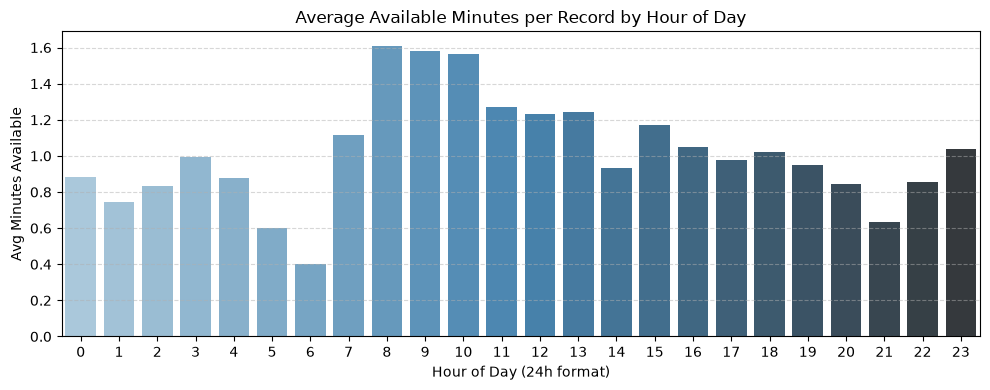


Peak availability window occurs around Hour: 8:00


In [12]:
# ---------------------------------------------------------
# Q3: What Time Are Units Usually Available? (Hourly Peak)
# ---------------------------------------------------------
hourly_avail = (
    df_avail.groupby('Hour')['Minutes_At_Status']
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 4))
sns.barplot(data=hourly_avail, x='Hour', y='Minutes_At_Status', palette='Blues_d')
plt.title("Average Available Minutes per Record by Hour of Day")
plt.xlabel("Hour of Day (24h format)")
plt.ylabel("Avg Minutes Available")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

peak_hour = hourly_avail.loc[hourly_avail['Minutes_At_Status'].idxmax(), 'Hour']
print(f"\nPeak availability window occurs around Hour: {peak_hour}:00")

/var/folders/d7/81r0zmfs5gx05dgv2v8ny96c0000gn/T/ipykernel_52031/2677327102.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=hourly_avail, x='Hour', y='Minutes_At_Status', palette='Blues_d')


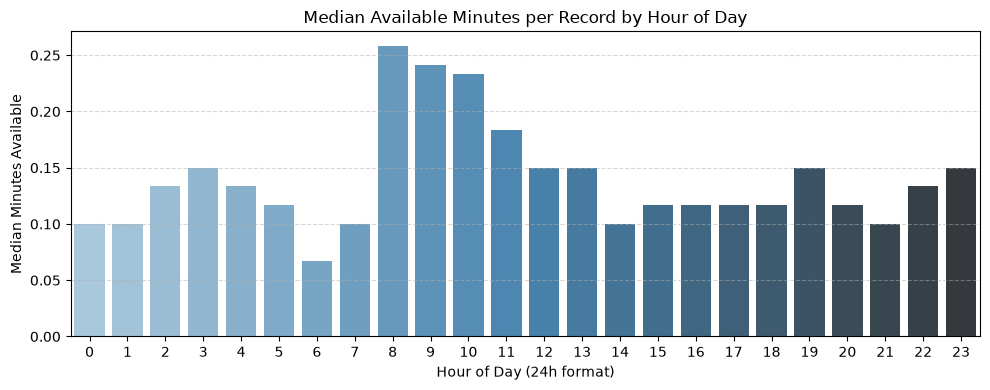


Peak availability window occurs around Hour: 8:00


In [32]:
# ---------------------------------------------------------
# Q3: What Time Are Units Usually Available? (Hourly Peak)
# ---------------------------------------------------------
hourly_avail = (
    df_avail.groupby('Hour')['Minutes_At_Status']
    .median()
    .reset_index()
)

plt.figure(figsize=(10, 4))
sns.barplot(data=hourly_avail, x='Hour', y='Minutes_At_Status', palette='Blues_d')
plt.title("Median Available Minutes per Record by Hour of Day")
plt.xlabel("Hour of Day (24h format)")
plt.ylabel("Median Minutes Available")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

peak_hour = hourly_avail.loc[hourly_avail['Minutes_At_Status'].idxmax(), 'Hour']
print(f"\nPeak availability window occurs around Hour: {peak_hour}:00")

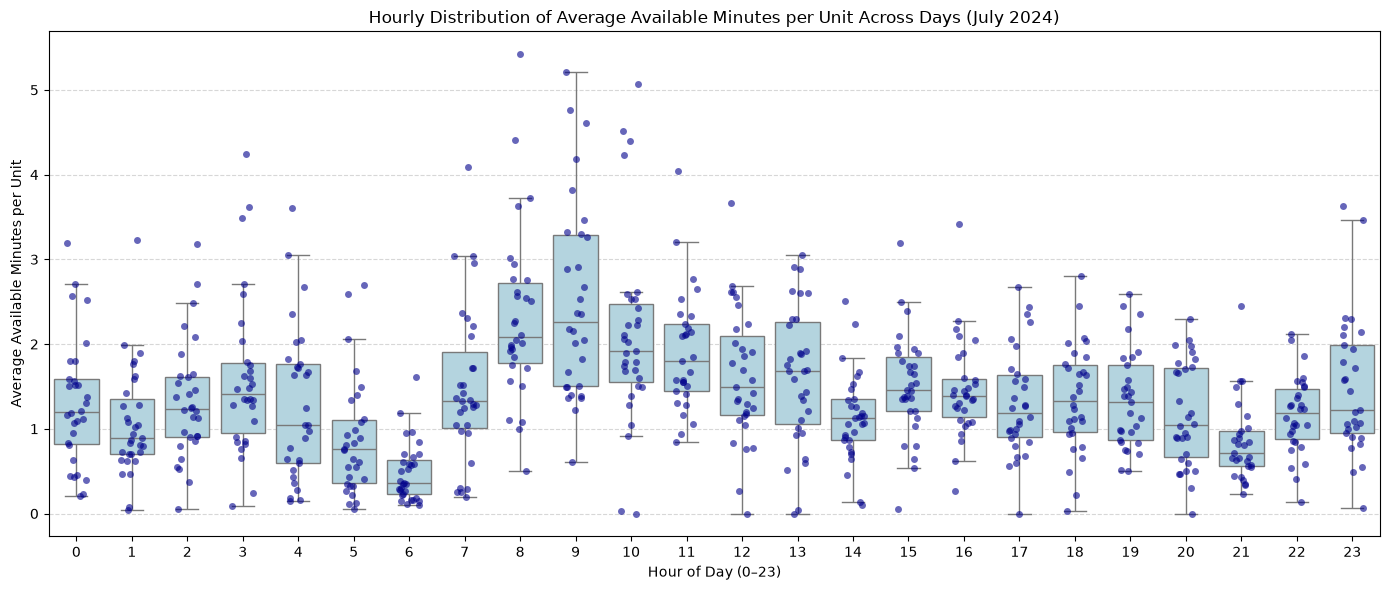

In [35]:
# ---------------------------------------------------------
# 2. Q3 Box Plot: Distribution per Hour (Dots = Each Day)
# ---------------------------------------------------------


# 1. Sum available minutes per unit for each (Date, Hour)
unit_hour_avail = (
    df_avail.groupby(['Date', 'Hour', 'Unit_ID'])['Minutes_At_Status']
    .sum()
    .reset_index()
)

# 2. Compute the AVERAGE (mean) across units for each day and hour
daily_hourly_mean = (
    unit_hour_avail.groupby(['Date', 'Hour'])['Minutes_At_Status']
    .mean()
    .reset_index()
)

# 3. Plot: Each dot represents 1 day's average unit availability for that hour
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=daily_hourly_mean,
    x='Hour',
    y='Minutes_At_Status',
    color='lightblue',
    showfliers=False
)
sns.stripplot(
    data=daily_hourly_mean,
    x='Hour',
    y='Minutes_At_Status',
    color='darkblue',
    alpha=0.6,
    jitter=0.2,
    size=5
)

plt.title("Hourly Distribution of Average Available Minutes per Unit Across Days (July 2024)")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Average Available Minutes per Unit")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

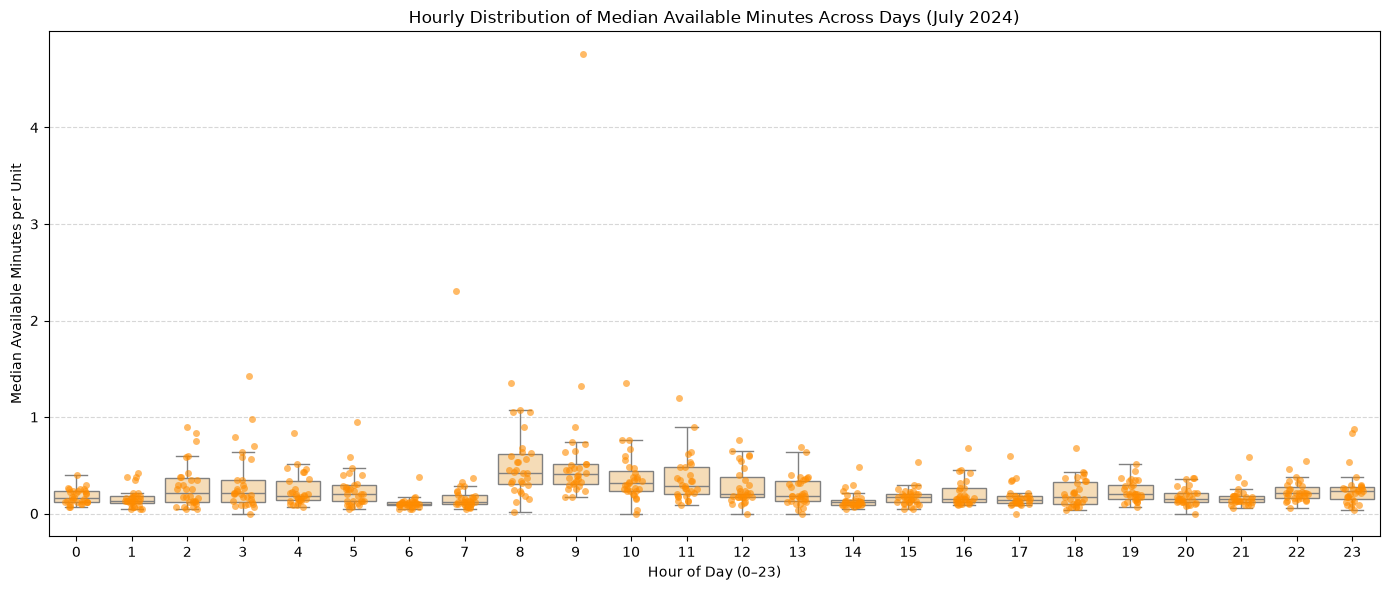

In [42]:
# 1. Compute the MEDIAN across units for each day and hour
daily_hourly_median = (
    unit_hour_avail.groupby(['Date', 'Hour'])['Minutes_At_Status']
    .median()
    .reset_index()
)

# 2. Plot: Each dot represents 1 day's median unit availability for that hour
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=daily_hourly_median,
    x='Hour',
    y='Minutes_At_Status',
    color='navajowhite',
    showfliers=False
)
sns.stripplot(
    data=daily_hourly_median,
    x='Hour',
    y='Minutes_At_Status',
    color='darkorange',
    alpha=0.6,
    jitter=0.2,
    size=5
)

plt.title("Hourly Distribution of Median Available Minutes Across Days (July 2024)")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Median Available Minutes per Unit")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

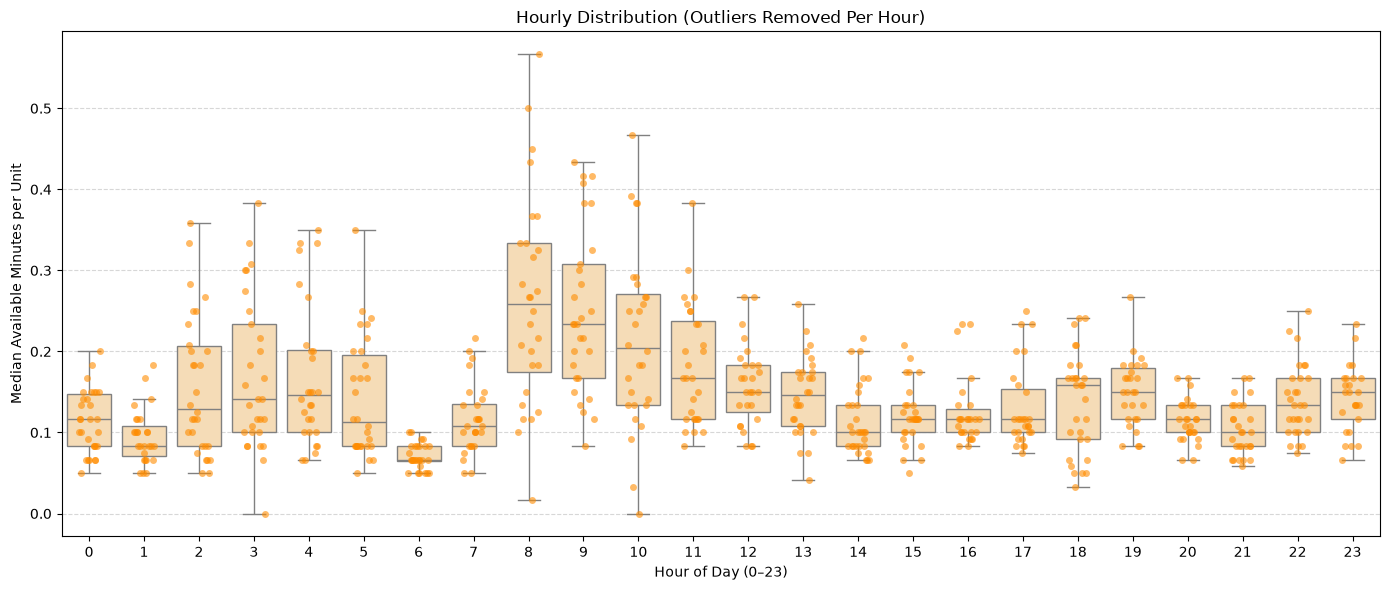

In [41]:
# 1. Compute IQR per hour
def remove_hourly_outliers(df, col='Minutes_At_Status'):
    q1 = df.groupby('Hour')[col].transform(lambda x: x.quantile(0.25))
    q3 = df.groupby('Hour')[col].transform(lambda x: x.quantile(0.75))
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return df[(df[col] >= lower) & (df[col] <= upper)]

filtered_hourly = remove_hourly_outliers(daily_hourly_median)

# 2. Plot
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=filtered_hourly,
    x='Hour',
    y='Minutes_At_Status',
    color='navajowhite',
    showfliers=False
)

sns.stripplot(
    data=filtered_hourly,
    x='Hour',
    y='Minutes_At_Status',
    color='darkorange',
    alpha=0.6,
    jitter=0.2,
    size=5
)

plt.title("Hourly Distribution (Outliers Removed Per Hour)")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Median Available Minutes per Unit")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

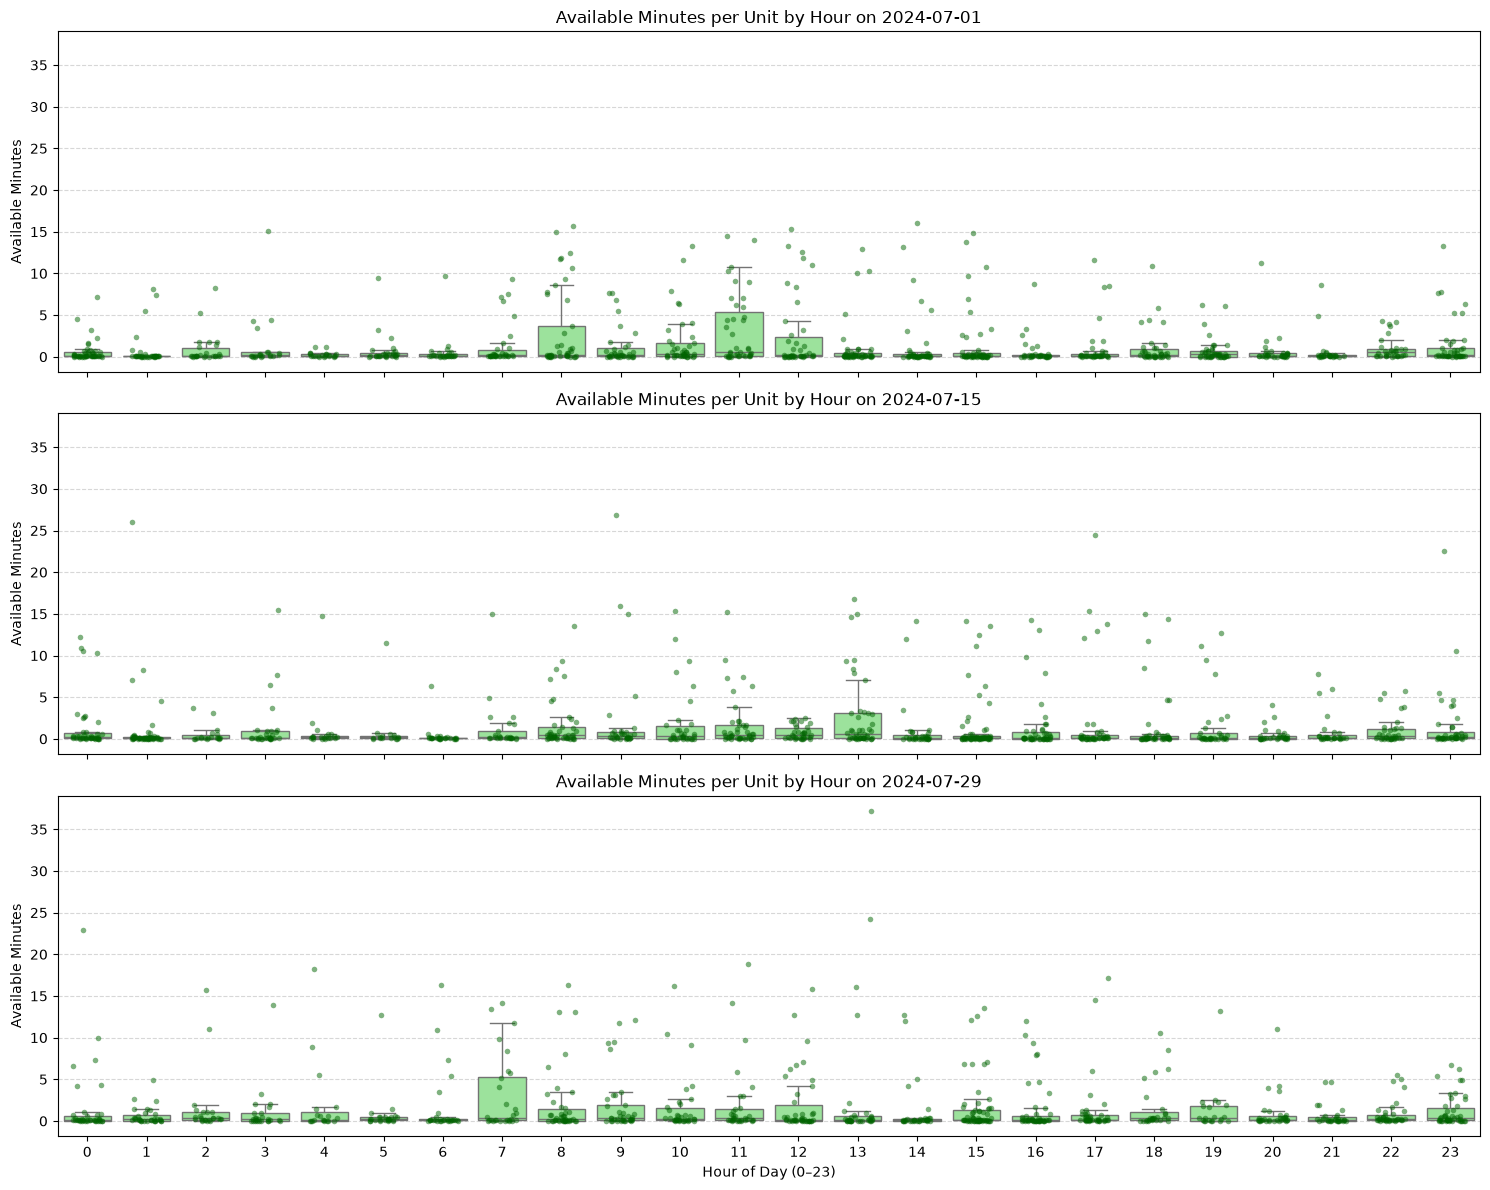

In [31]:
# ---------------------------------------------------------
# 3. Box Plot for 3 Different Days (Dots = Each Unit)
# ---------------------------------------------------------
# Calculate total available minutes per unit in each hour
unit_hour_avail = (
    df_avail.groupby(['Date', 'Hour', 'Unit_ID'])['Minutes_At_Status']
    .sum()
    .reset_index()
)

# Select 3 days to compare (e.g., beginning, middle, and end of the month)
selected_dates = [
    pd.to_datetime('2024-07-01').date(),
    pd.to_datetime('2024-07-15').date(),
    pd.to_datetime('2024-07-29').date()
]

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True, sharey=True)

for ax, d in zip(axes, selected_dates):
    day_subset = unit_hour_avail[unit_hour_avail['Date'] == d]
    
    # Box plot showing the unit distribution for that specific day
    sns.boxplot(
        data=day_subset,
        x='Hour',
        y='Minutes_At_Status',
        ax=ax,
        color='lightgreen',
        showfliers=False
    )
    # Overlay strip plot: each dot represents an individual unit in that hour
    sns.stripplot(
        data=day_subset,
        x='Hour',
        y='Minutes_At_Status',
        ax=ax,
        color='darkgreen',
        alpha=0.5,
        jitter=0.25,
        size=4
    )
    ax.set_title(f"Available Minutes per Unit by Hour on {d}")
    ax.set_ylabel("Available Minutes")
    ax.set_xlabel("Hour of Day (0–23)")
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

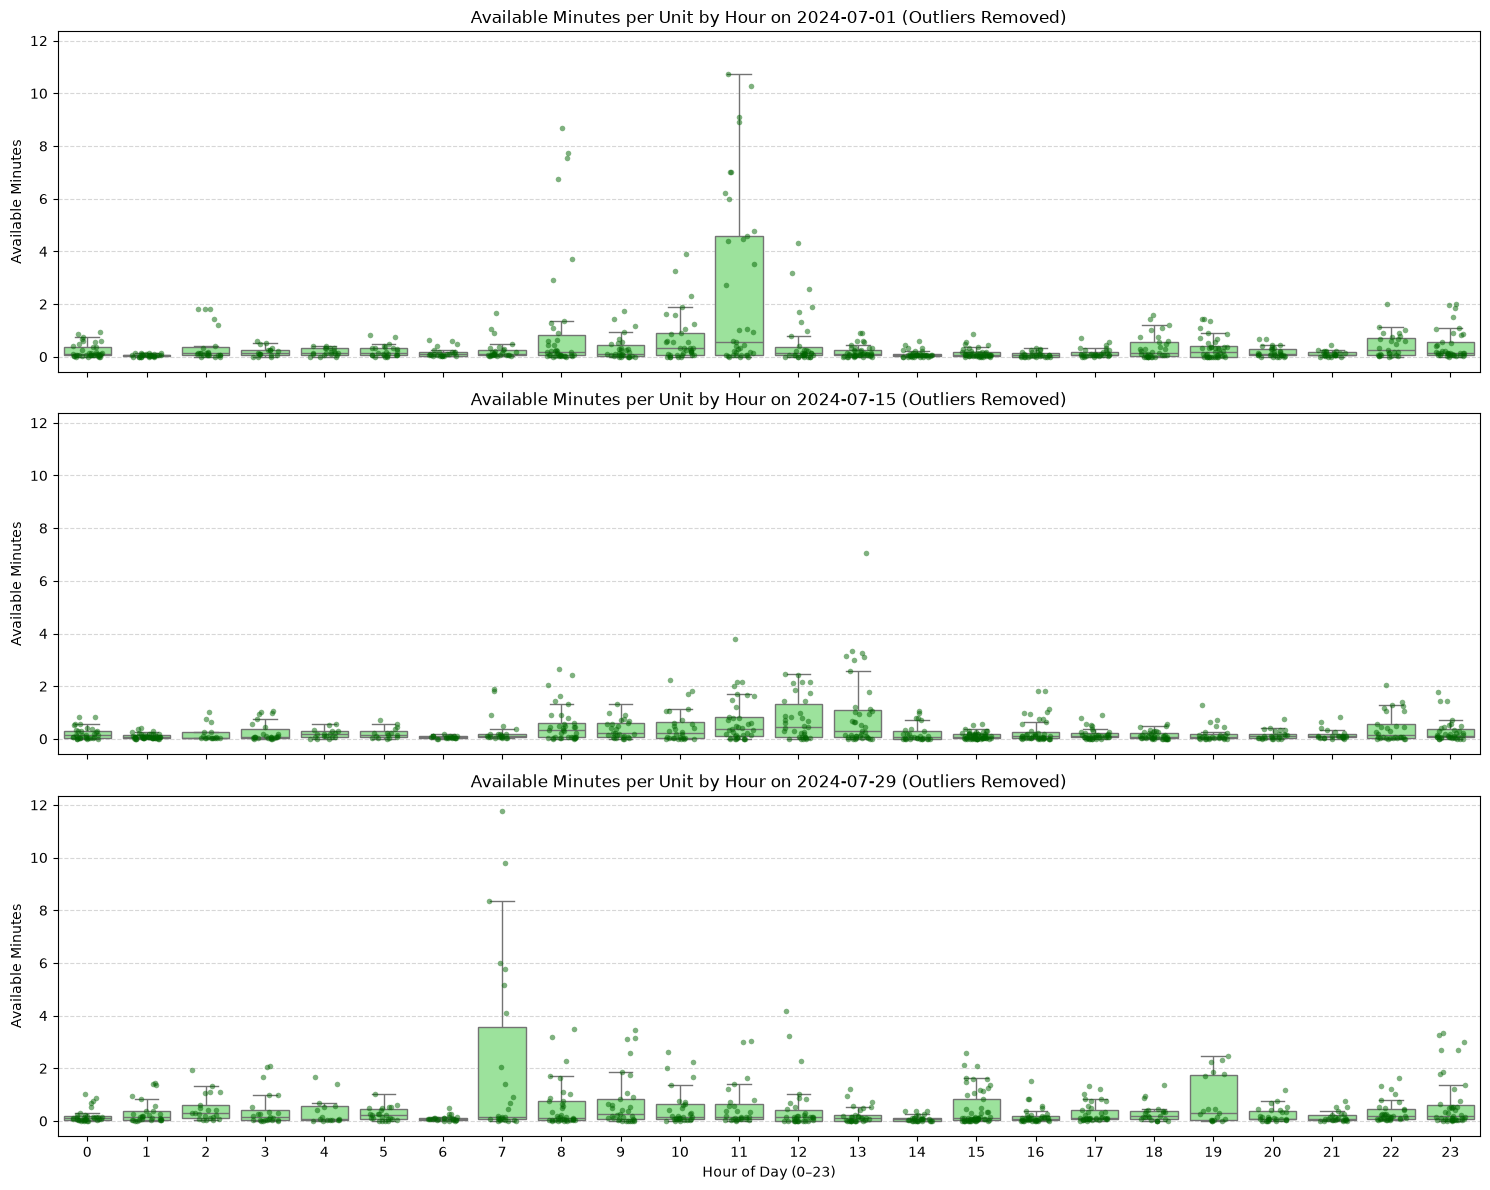

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Function to filter outliers per hour for a given day
def remove_hourly_outliers(df, col='Minutes_At_Status'):
    q1 = df.groupby('Hour')[col].transform(lambda x: x.quantile(0.25))
    q3 = df.groupby('Hour')[col].transform(lambda x: x.quantile(0.75))
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return df[(df[col] >= lower) & (df[col] <= upper)]

# Calculate unit hourly availability
unit_hour_avail = (
    df_avail.groupby(['Date', 'Hour', 'Unit_ID'])['Minutes_At_Status']
    .sum()
    .reset_index()
)

selected_dates = [
    pd.to_datetime('2024-07-01').date(),
    pd.to_datetime('2024-07-15').date(),
    pd.to_datetime('2024-07-29').date()
]

# Set sharey=False if you want each day to zoom independently into its own active range
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True, sharey=True)

for ax, d in zip(axes, selected_dates):
    day_subset = unit_hour_avail[unit_hour_avail['Date'] == d]
    
    # Filter out outliers for this specific day
    filtered_day_subset = remove_hourly_outliers(day_subset)
    
    # Box plot on filtered data
    sns.boxplot(
        data=filtered_day_subset,
        x='Hour',
        y='Minutes_At_Status',
        ax=ax,
        color='lightgreen',
        showfliers=False
    )
    
    # Strip plot on filtered data (no outlier dots)
    sns.stripplot(
        data=filtered_day_subset,
        x='Hour',
        y='Minutes_At_Status',
        ax=ax,
        color='darkgreen',
        alpha=0.5,
        jitter=0.25,
        size=4
    )
    
    ax.set_title(f"Available Minutes per Unit by Hour on {d} (Outliers Removed)")
    ax.set_ylabel("Available Minutes")
    ax.set_xlabel("Hour of Day (0–23)")
    ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Missing Beat Values: In CAD data, availability rows recorded as USAV frequently have NaN for Beat because the vehicle is not assigned to an incident. If Beat is populated under incident-related statuses (e.g., FR), forward-fill (ffill()) by Unit_ID ordered chronologically so each unit carries its assigned beat during patrol:

In [24]:
df_avail = df_avail.sort_values(['Unit_ID', 'Manpower_Record_Time'])
df_avail['Beat'] = df_avail['Unit_ID'].str.extract(r'(\d{2})$')[0]

/var/folders/d7/81r0zmfs5gx05dgv2v8ny96c0000gn/T/ipykernel_52031/2273577524.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


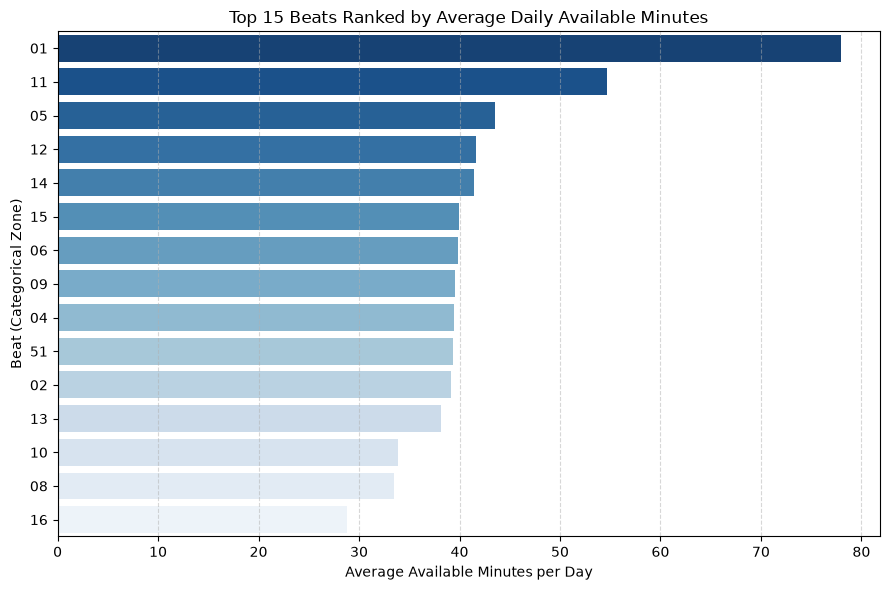

In [28]:
# ---------------------------------------------------------
# Q4: Which Beat Has the Most Available Units on Average?
# ---------------------------------------------------------
# Fill missing beats if mapped downstream or filter valid beat entries
beat_df = df_avail[df_avail['Beat'].notna()].copy()

# Aggregate average daily available minutes per beat
beat_summary = (
    beat_df.groupby(['Beat', 'Date'])['Minutes_At_Status']
    .sum()
    .groupby('Beat')
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

# Pick the top 15 beats with the highest availability
top_beats = beat_summary.head(15)

plt.figure(figsize=(9, 6))
# Setting Beat on the y-axis treats each beat purely as a discrete categorical label
sns.barplot(
    data=top_beats,
    y='Beat',
    x='Minutes_At_Status',
    palette='Blues_r'
)

plt.title("Top 15 Beats Ranked by Average Daily Available Minutes")
plt.xlabel("Average Available Minutes per Day")
plt.ylabel("Beat (Categorical Zone)")
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [39]:
import numpy as np
import pandas as pd

# Load and sort chronologically per unit
MANPOWER = BOX_ROOT / "00_one_percent" 
df = pd.read_csv(MANPOWER / "Man_Power_2024_July.csv")

df["Manpower_Record_Time"] = pd.to_datetime(df["Manpower_Record_Time"])
if df["Seconds_At_Status"].dtype == "object":
  df["Seconds_At_Status"] = (
      df["Seconds_At_Status"].astype(str).str.replace(",", "", regex=False)
  )
df["Seconds_clean"] = (
    pd.to_numeric(df["Seconds_At_Status"], errors="coerce").fillna(0)
)
df["Minutes_clean"] = df["Seconds_clean"] / 60.0

df_sorted = df.sort_values(
    ["Unit_ID", "Manpower_Record_Time", "Unnamed: 0"]
).copy()

# Look ahead to the subsequent event
df_sorted["next_code"] = df_sorted.groupby("Unit_ID")["Code"].shift(-1)
df_sorted["next_incident"] = df_sorted.groupby("Unit_ID")["Incident_FK"].shift(
    -1
)

# Filter for available status (USAV, FR) directly preceding a task assignment
is_available = df_sorted["Code"].isin(["USAV", "FR"])
is_followed_by_task = df_sorted["next_code"].isin([
    "D",
    "USER",
    "USOS",
]) | df_sorted["next_incident"].notna()

avail_to_task = df_sorted[is_available & is_followed_by_task].copy()

# Aggregate per unit
unit_availability_summary = (
    avail_to_task.groupby("Unit_ID")
    .agg(
        total_assignments=("Minutes_clean", "count"),
        median_available_mins=("Minutes_clean", "median"),
        mean_available_mins=("Minutes_clean", "mean"),
        p75_available_mins=("Minutes_clean", lambda x: np.percentile(x, 75)),
        p90_available_mins=("Minutes_clean", lambda x: np.percentile(x, 90)),
        max_available_mins=("Minutes_clean", "max"),
    )
    .reset_index()
    .sort_values("total_assignments", ascending=False)
)

# Display top 20 most active units
print(unit_availability_summary.head(20))

    Unit_ID  total_assignments  median_available_mins  mean_available_mins  \
285    2L04                330               0.150000             0.966364   
409    3L08                305               0.200000             1.593279   
388    3A32                298               0.333333             0.640828   
300    2L19                286               0.116667             0.310198   
287    2L06                281               0.316667             1.512040   
414    3L13                271               0.216667             0.855474   
411    3L10                268               0.283333             1.538495   
137    1L11                249               0.283333             1.570348   
296    2L15                246               0.166667             0.912873   
128    1L02                245               0.183333             1.515374   
365    3A05                242               0.333333             1.530372   
140    1L14                235               0.116667           

In [40]:
import numpy as np
import pandas as pd

# ----------------------------------------------------------------------
# 1. Load Data & Clean Status Durations
# ----------------------------------------------------------------------
MANPOWER = BOX_ROOT / "00_one_percent" 
df = pd.read_csv(MANPOWER / "Man_Power_2024_July.csv")

df["Manpower_Record_Time"] = pd.to_datetime(df["Manpower_Record_Time"])

# Remove formatting commas from numerical duration strings
if df["Seconds_At_Status"].dtype == "object":
  df["Seconds_At_Status"] = (
      df["Seconds_At_Status"].astype(str).str.replace(",", "", regex=False)
  )

df["Seconds_clean"] = pd.to_numeric(
    df["Seconds_At_Status"], errors="coerce"
).fillna(0)
df["Minutes_clean"] = df["Seconds_clean"] / 60.0

# Chronological sort per unit
df_sorted = df.sort_values(
    ["Unit_ID", "Manpower_Record_Time", "Unnamed: 0"]
).copy()

# Look ahead to identify the next event status and incident assignment
df_sorted["next_code"] = df_sorted.groupby("Unit_ID")["Code"].shift(-1)
df_sorted["next_incident"] = df_sorted.groupby("Unit_ID")["Incident_FK"].shift(
    -1
)

# ----------------------------------------------------------------------
# 2. Filter: Available Status Directly Preceding a New Task
# ----------------------------------------------------------------------
is_available = df_sorted["Code"].isin(["USAV", "FR"])
is_task_assignment = df_sorted["next_code"].isin([
    "D",
    "USER",
    "USOS",
]) | df_sorted["next_incident"].notna()

avail_to_task = df_sorted[is_available & is_task_assignment].copy()

# ----------------------------------------------------------------------
# Table 1: Department-Wide Availability Distribution
# ----------------------------------------------------------------------
percentiles = [
    ("Minimum", 0),
    ("10th Percentile", 10),
    ("25th Percentile (Q1)", 25),
    ("50th Percentile (Median)", 50),
    ("75th Percentile (Q3)", 75),
    ("90th Percentile", 90),
    ("95th Percentile", 95),
]

dept_rows = []
for label, p in percentiles:
  sec_val = np.percentile(avail_to_task["Seconds_clean"], p)
  min_val = np.percentile(avail_to_task["Minutes_clean"], p)
  if sec_val < 60:
    time_str = f"{sec_val:.0f} seconds ({min_val:.2f} min)"
  else:
    time_str = f"{min_val:.1f} minutes"
  dept_rows.append({"Metric": label, "Time Available": time_str})

# Add overall mean
mean_min = avail_to_task["Minutes_clean"].mean()
dept_rows.append(
    {"Metric": "Overall Mean", "Time Available": f"{mean_min:.1f} minutes"}
)

table_1_dept_wide = pd.DataFrame(dept_rows)
print("=== Table 1: Department-Wide Availability Distribution ===")
print(table_1_dept_wide.to_string(index=False))
print("\n" + "=" * 60 + "\n")

# ----------------------------------------------------------------------
# Table 2: Unit-Level Differences: Two Operating Regimes Summary
# ----------------------------------------------------------------------
# Aggregate availability metrics per individual unit
unit_stats = (
    avail_to_task.groupby("Unit_ID")
    .agg(
        total_assignments=("Minutes_clean", "count"),
        median_available_mins=("Minutes_clean", "median"),
        median_available_secs=("Seconds_clean", "median"),
        mean_available_mins=("Minutes_clean", "mean"),
        p75_available_mins=("Minutes_clean", lambda x: np.percentile(x, 75)),
        p75_available_secs=("Seconds_clean", lambda x: np.percentile(x, 75)),
        p90_available_mins=("Minutes_clean", lambda x: np.percentile(x, 90)),
    )
    .reset_index()
)

# Active units: active operational baseline (>= 20 assignments)
active_units = unit_stats[unit_stats["total_assignments"] >= 20].copy()

table_2_regimes = pd.DataFrame([
    {
        "Metric": "Active Units (>= 20 assignments)",
        "Summary Value": f"n = {len(active_units)}",
    },
    {
        "Metric": "Median of Medians across active units",
        "Summary Value": (
            f"{active_units['median_available_secs'].median():.1f} sec"
            f" ({active_units['median_available_mins'].median():.2f} min)"
        ),
    },
    {
        "Metric": "Mean of Medians across active units",
        "Summary Value": f"{active_units['median_available_mins'].mean():.2f} min",
    },
    {
        "Metric": "Median of Means across active units",
        "Summary Value": f"{active_units['mean_available_mins'].median():.2f} min",
    },
    {
        "Metric": "Mean of Means across active units",
        "Summary Value": f"{active_units['mean_available_mins'].mean():.2f} min",
    },
])

print("=== Table 2: Unit-Level Differences: Two Operating Regimes ===")
print(table_2_regimes.to_string(index=False))
print("\n" + "=" * 60 + "\n")

# ----------------------------------------------------------------------
# Table 3: High-Activity Frontline Patrol Units (Lowest Median Idle Time)
# ----------------------------------------------------------------------
frontline_top = active_units.sort_values(
    ["median_available_mins", "total_assignments"], ascending=[True, False]
).head(8)

table_3_frontline = pd.DataFrame({
    "Unit ID": frontline_top["Unit_ID"],
    "Monthly Assignments": frontline_top["total_assignments"],
    "Typical (Median) Available Time": frontline_top.apply(
        lambda r: (
            f"{r['median_available_secs']:.1f} sec"
            f" ({r['median_available_mins']:.2f} min)"
        ),
        axis=1,
    ),
    "75th Percentile": frontline_top.apply(
        lambda r: (
            f"{r['p75_available_secs']:.1f} sec"
            if r["p75_available_secs"] < 60
            else f"{r['p75_available_mins']:.2f} min"
        ),
        axis=1,
    ),
    "Mean Available Time": frontline_top.apply(
        lambda r: (
            f"{r['mean_available_mins'] * 60:.1f} sec"
            if r["mean_available_mins"] < 1
            else f"{r['mean_available_mins']:.2f} min"
        ),
        axis=1,
    ),
})

print(
    "=== Table 3: High-Activity Frontline Patrol Units (Immediate Queue Backlog)"
    " ==="
)
print(table_3_frontline.to_string(index=False))
print("\n" + "=" * 60 + "\n")

# ----------------------------------------------------------------------
# Table 4: Specialized, Administrative, and Specialty Detail Units
# ----------------------------------------------------------------------
specialized_top = active_units.sort_values(
    "median_available_mins", ascending=False
).head(10)

table_4_specialized = pd.DataFrame({
    "Unit ID": specialized_top["Unit_ID"],
    "Monthly Assignments": specialized_top["total_assignments"],
    "Typical (Median) Available Time": specialized_top[
        "median_available_mins"
    ].map(lambda x: f"{x:.1f} min"),
    "75th Percentile": specialized_top["p75_available_mins"].map(
        lambda x: f"{x:.1f} min"
    ),
    "Mean Available Time": specialized_top["mean_available_mins"].map(
        lambda x: f"{x:.1f} min"
    ),
})

print(
    "=== Table 4: Specialized, Administrative, and Specialty Detail Units ==="
)
print(table_4_specialized.to_string(index=False))

=== Table 1: Department-Wide Availability Distribution ===
                  Metric        Time Available
                 Minimum  0 seconds (0.00 min)
         10th Percentile  1 seconds (0.02 min)
    25th Percentile (Q1)  3 seconds (0.05 min)
50th Percentile (Median) 10 seconds (0.17 min)
    75th Percentile (Q3) 40 seconds (0.67 min)
         90th Percentile           3.4 minutes
         95th Percentile           6.9 minutes
            Overall Mean           1.1 minutes


=== Table 2: Unit-Level Differences: Two Operating Regimes ===
                               Metric       Summary Value
     Active Units (>= 20 assignments)             n = 316
Median of Medians across active units 11.0 sec (0.18 min)
  Mean of Medians across active units            0.31 min
  Median of Means across active units            0.94 min
    Mean of Means across active units            1.17 min


=== Table 3: High-Activity Frontline Patrol Units (Immediate Queue Backlog) ===
Unit ID  Monthly Assign